# 00 · Qué datos tenemos y qué pueden sostener

> **Lugar en el argumento:** punto de partida. Antes de interpretar variantes, este notebook
> separa las preguntas contestables de las que requieren una modalidad que no existe.
>
> **Salida principal:** QC de secuenciación medido + inventario de modalidades disponibles y
> ausentes. No intenta priorizar genes.

> **Saneado:** ninguna ruta local, ningún identificador de muestra, ninguna coordenada.
>
> **Sustituye a `00_data_inventory.ipynb`**, una plantilla sin ejecutar que apuntaba a un
> `../data` inexistente. Se conserva en `docs/history/`.

## Pregunta

**¿Los datos que hay son aptos, y para qué preguntas alcanzan?**

Dos preguntas distintas. La primera se responde con QC sobre el FASTQ. La segunda, con el
inventario de lo que existe y lo que no.

### Integración visual · 24 septiembre 2026

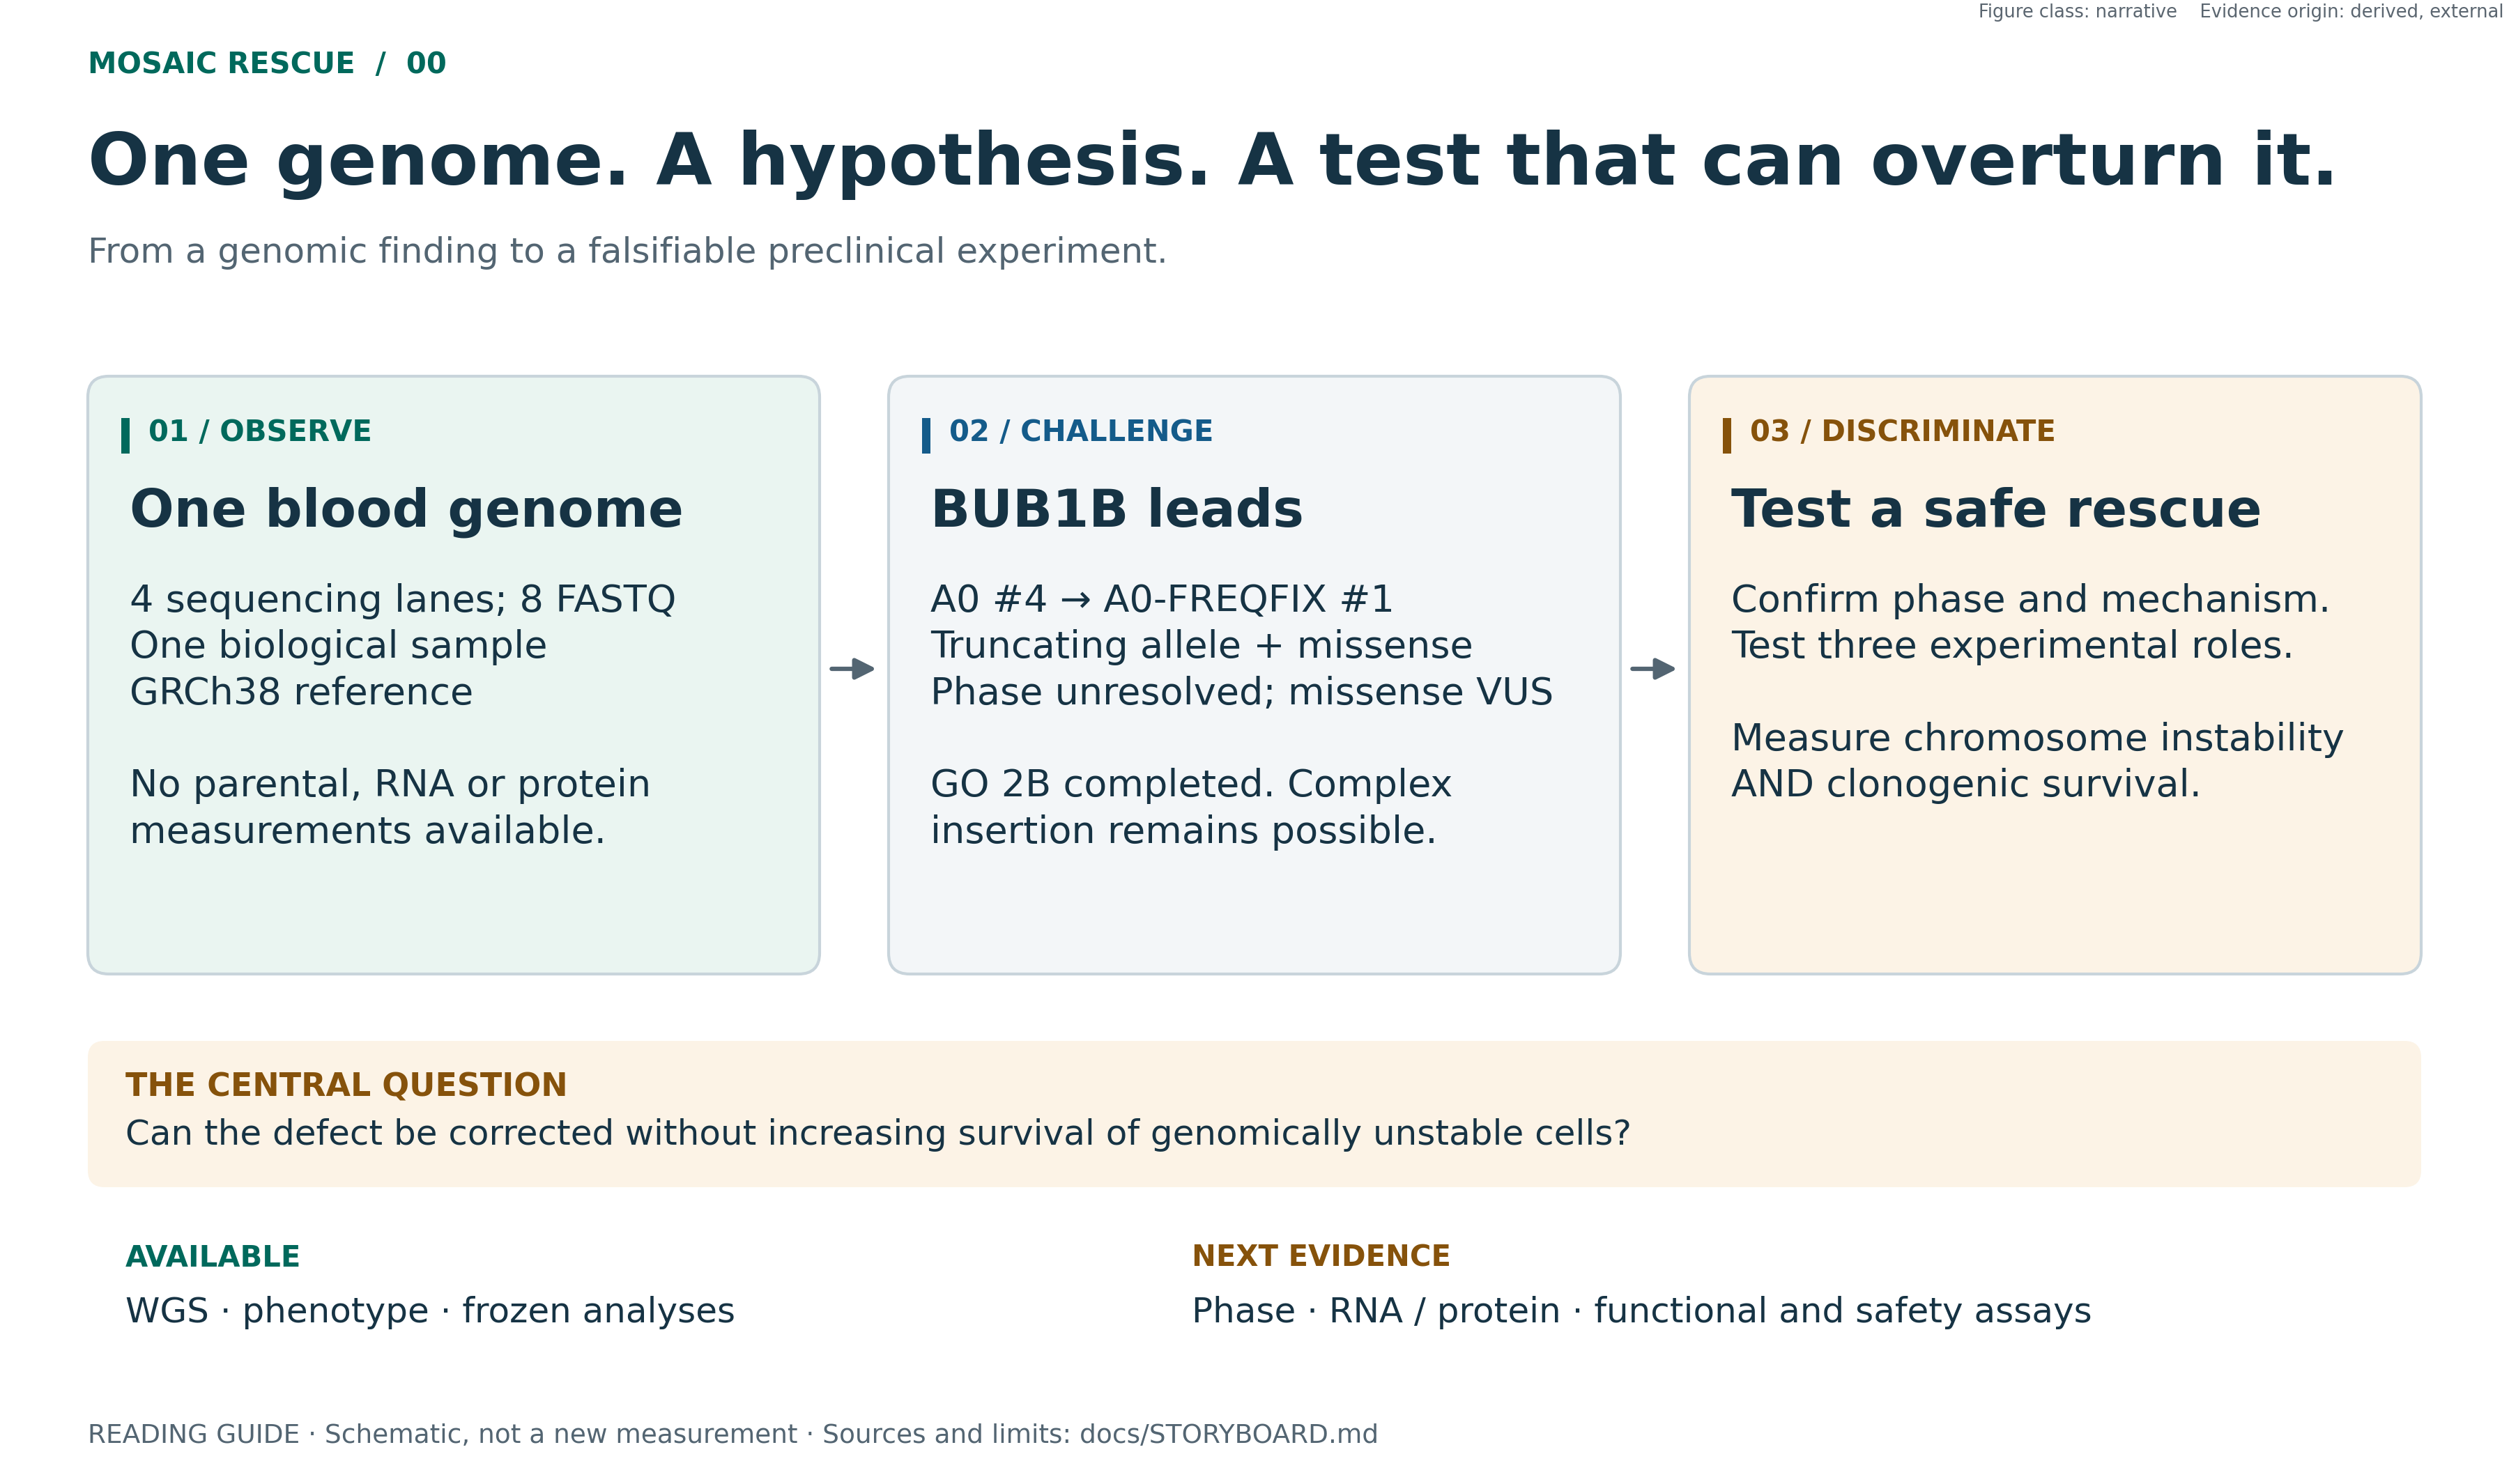

**NARRATIVE · DERIVED / EXTERNAL.** Una muestra biológica, cuatro carriles técnicos. El BAM completo ya existe; el QC original de abajo conserva su alcance L001.

Figura importada del artefacto revisado, sin reejecutar el análisis original. [Fuentes y límites](../docs/STORYBOARD.md) · [QA](../PUBLICATION_FIGURE_QA.md).

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


In [2]:
fl.labels("Lectura", "Hasta donde llega")

## QC de secuenciación, calculado, no citado

Una submuestra reproducible de L001 R1. Se recorren las lecturas una vez y se acumulan los
estadísticos por ciclo; nada viene del brief.

In [3]:
from src.figures import fig00_qc as F
from src.paths import get, patient_vcf

fq1 = get("patient", "fastq_l001_r1")
N = F.N_DEFAULT                  # submuestra reproducible: los estadisticos son agregados

# Un solo recorrido del FASTQ, el MISMO que usa la figura de publicacion. Antes
# el notebook y la figura tenian dos implementaciones del escaneo; podian
# divergir, y una figura que no reproduce lo que imprime su notebook no vale.
D = F.scan(fq1, n_reads=N)

n, CYC = D["n_reads"], D["cycles"]
gcarr = D["gc"]
median_readq = float(np.median(D["read_mean_q"]))
non_top_first, non_top_last = float(D["non_top"][0]), float(D["non_top"][-1])

print(f"  lecturas muestreadas   : {n:,}")
print(f"  longitud de lectura    : {CYC} pb  ·  valores distintos: {len(D['lengths'])}")
print(f"  bins de calidad        : {len(D['levels'])} -> "
      + ", ".join("Q" + str(v) for v in D["levels"]))
print(f"  fuera del bin alto     : {non_top_first:.2f} % en el ciclo 1  ->  "
      f"{non_top_last:.2f} % en el {CYC}")
print(f"  GC medio por lectura   : {gcarr.mean():.1f} %  (sd {gcarr.std():.1f})")
print(f"  calidad media/lectura  : mediana {median_readq:.1f}  ·  "
      f"{100 * float((D['read_mean_q'] < 30).mean()):.1f} % por debajo de Q30")
print(f"  bases >= Q30           : {D['q30_pct']:.1f} %")

  lecturas muestreadas   : 300,000
  longitud de lectura    : 149 pb  ·  valores distintos: 1
  bins de calidad        : 4 -> Q2, Q11, Q25, Q37
  fuera del bin alto     : 4.52 % en el ciclo 1  ->  13.29 % en el 149
  GC medio por lectura   : 41.3 %  (sd 10.2)
  calidad media/lectura  : mediana 36.5  ·  3.0 % por debajo de Q30
  bases >= Q30           : 92.9 %


### Figura científica 1 · QC de secuenciación por ciclo

Los cuatro paneles que se miran en cualquier informe de QC real. **Calculados aquí**, no
citados: calidad por ciclo con su dispersión, GC por lectura frente a la distribución teórica,
longitud, y composición de bases por ciclo.

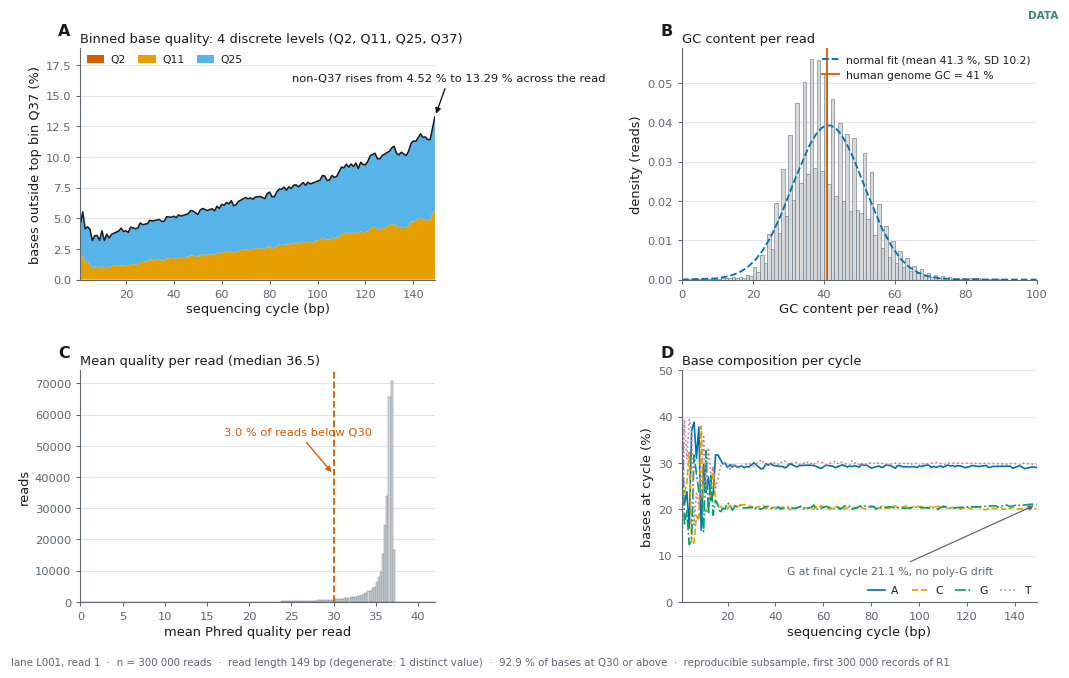

> **Figura 1 · QC de secuenciacion de L001**  
> `EXP-001` · figure class `DATA`, figura cientifica · evidence origin `MEASURED`  
> *Lectura.* la degradacion real a lo largo de la lectura. Este secuenciador entrega calidades BINADAS en cuatro valores (Q2, Q11, Q25, Q37) y lo que informa es la masa que ABANDONA el bin alto: de 4.52 % en el ciclo 1 a 13.29 % en el 149. Ademas: GC por lectura centrado en 41.3 % contra el 41 % del genoma humano, calidad media por lectura con mediana 36.5, y composicion de bases estable sin deriva poly-G al final del read.  
> **Hasta donde llega.** que los datos sean SUFICIENTES. El QC dice que son aptos, no que alcancen para las preguntas que quedan. Y no dice nada del tipo de libreria: PCR-free o DNA Prep comparten adaptador, y eso sigue sin respuesta.  
> datos: `submuestra reproducible de 300,000 lecturas de L001 R1` · libreria: `matplotlib` · procedencia: `figures/pub/fig00_fastq_qc.svg + .png 300 dpi`

In [4]:
from src.figures import fig00_qc as F

fig = F.build(F.scan(fq1, n_reads=N))
fl.pub(fig, "Figura 1 · QC de secuenciacion de L001", "EXP-001", "MEASURED", "DATA",
       f"la degradacion real a lo largo de la lectura. Este secuenciador entrega calidades "
       f"BINADAS en cuatro valores (Q2, Q11, Q25, Q37) y lo que informa es la masa que "
       f"ABANDONA el bin alto: de {non_top_first:.2f} % en el ciclo 1 a {non_top_last:.2f} % "
       f"en el {CYC}. Ademas: GC por lectura centrado en {gcarr.mean():.1f} % contra el 41 % "
       f"del genoma humano, calidad media por lectura con mediana {median_readq:.1f}, y "
       f"composicion de bases estable sin deriva poly-G al final del read.",
       "que los datos sean SUFICIENTES. El QC dice que son aptos, no que alcancen para las "
       "preguntas que quedan. Y no dice nada del tipo de libreria: PCR-free o DNA Prep "
       "comparten adaptador, y eso sigue sin respuesta.",
       source=f"submuestra reproducible de {n:,} lecturas de L001 R1",
       lib="matplotlib", slug="fig00_fastq_qc")

## Inventario de modalidades, metadata, no un objeto científico

Esto **no** es una figura científica y se etiqueta como tal. Es el límite de lo que el
proyecto puede afirmar, y se comprueba en disco, no se declara.

In [5]:
import glob
def size_gb(p):
    return os.path.getsize(p) / 2**30 if p and os.path.exists(p) else None

vcf = patient_vcf()
lanes = sorted(glob.glob(os.path.dirname(fq1) + "/*_L00[2-4]_R[12]_*.fastq.gz"))
MOD = [
    ("VCF de WGS",                 os.path.exists(vcf),  f"{size_gb(vcf):.2f} GB"),
    ("FASTQ L001 (R1)",            os.path.exists(fq1),  f"{size_gb(fq1):.1f} GB"),
    ("FASTQ L002-L004",            len(lanes) > 0,       f"{len(lanes)} en disco"),
    ("BAM / CRAM profundidad completa",
     len(glob.glob("work/**/*.cram", recursive=True)
         + glob.glob("work/**/*.bam", recursive=True)) > 0, "-"),
    ("Genotipos parentales",       False, "no entregados"),
    ("RNA-seq",                    False, "no existe"),
    ("Single-cell",                False, "no existe"),
    ("Proteomica",                 False, "no existe"),
    ("Tejido tumoral",             False, "no entregado"),
    ("Cariotipo / array previo",   False, "no entregado"),
    ("Hemograma contemporaneo",    False, "pedido, sin respuesta"),
    ("Fenotipo HPO",               os.path.exists("config/phenotype_v2.yaml"), "7 + 1 terminos"),
]
for name, present, note in MOD:
    print(f"  {'SI ' if present else 'NO '} {name:<34} {note}")

  SI  VCF de WGS                         0.29 GB
  SI  FASTQ L001 (R1)                    9.7 GB
  NO  FASTQ L002-L004                    0 en disco
  NO  BAM / CRAM profundidad completa    -
  NO  Genotipos parentales               no entregados
  NO  RNA-seq                            no existe
  NO  Single-cell                        no existe
  NO  Proteomica                         no existe
  NO  Tejido tumoral                     no entregado
  NO  Cariotipo / array previo           no entregado
  NO  Hemograma contemporaneo            pedido, sin respuesta
  SI  Fenotipo HPO                       7 + 1 terminos


## Decisión

| | |
|---|---|
| **Los datos son aptos** | longitud invariante, GC en rango, Q30 alto, sin deriva poly-G |
| **No son suficientes** | 5 de 16 ramas bloqueadas por modalidades ausentes |

### Qué NO demuestra este notebook

Que las modalidades ausentes vayan a llegar, ni que los datos presentes alcancen para las
preguntas abiertas. **Y prohibido cerrar un negativo con L001**: un carril a ~13× es piloto.

### Falsificador

Si aparece cualquiera de las modalidades marcadas ausente, hay que reejecutarlo. Está
construido para eso: **ningún valor está escrito a mano**.

### Siguiente experimento

`01_TRACK1_GENOME_WIDE`.

In [6]:
fl.summary()

  figuras: 1  ·  cientificas: 1  ·  narrativa/sintesis: 0

  clase         evidencia             libreria            titulo
  ------------------------------------------------------------------------------------------------
  DATA          MEASURED              matplotlib          Figura 1 · QC de secuenciacion de L001
